# Week2_ex3 Analysis — How PowerWorld Applies the PST Impedance Correction Table

Deep dive on Problem 3.62b from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.). The phase-shifting transformer carries an impedance correction table (x2.0 at -30°, x1.0 at 0°, x2.0 at +30°), and the one-line reports the series reactance growing from 0.250 to 0.333 pu at +10°. The open question is whether the multiplier touches only the reactance or the whole impedance:

$$\text{H1: } Z(\theta) = R + j\,k(\theta)\,X \qquad \text{H2: } Z(\theta) = k(\theta)\,(R + jX)$$

with $k(\theta)$ interpolated linearly between the table points, so $k(10°) = 1 + 10/30 = 1.333$. With $R = 0.01$ and $X = 0.25$ pu, H1 keeps $R = 0.01$ while H2 raises it to $0.0133$ pu. The extra resistance is small next to the reactance, but it sits directly in $I^2 R$, so the real power loss is where the two readings should separate.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandapower as pp

# 1. Case data read once from PowerWorld Simulator (Run Mode, Model Explorer > Network > Branches Input,
#    Impedance Correction Tables; Simulator Options > Power Flow Solution > General)
S_BASE = 500.0
V_KV = 345.0
Z_BASE = V_KV**2 / S_BASE
R_LINE, X_LINE = 0.03, 0.20
R_PST, X_PST = 0.01, 0.25
CORR_ANGLE = [-30.0, 0.0, 30.0]
CORR_FACTOR = [2.0, 1.0, 2.0]
MVA_TOL = 0.5   # PowerWorld MVA convergence tolerance

steps = np.arange(-30, 31)
k = np.interp(steps, CORR_ANGLE, CORR_FACTOR)

pd.DataFrame({
    "Angle [deg]": [-30, -10, 0, 10, 30],
    "k [-]": np.interp([-30, -10, 0, 10, 30], CORR_ANGLE, CORR_FACTOR),
}).assign(**{
    "H1 R [pu]": R_PST,
    "H2 R [pu]": lambda d: R_PST * d["k [-]"],
    "X [pu] (both)": lambda d: X_PST * d["k [-]"],
}).round(4)

,Angle [deg],k [-],H1 R [pu],H2 R [pu],X [pu] (both)
0,-30,2.0000,0.01,0.0200,0.5000
1,-10,1.3333,0.01,0.0133,0.3333
2,0,1.0000,0.01,0.0100,0.2500
3,10,1.3333,0.01,0.0133,0.3333
4,30,2.0000,0.01,0.0200,0.5000


In [2]:
# 2. One builder for both hypotheses: only the resistance column of the characteristic table differs
def build_case(angle_deg, scale_r):
    net = pp.create_empty_network(f_hz=60, sn_mva=S_BASE)
    gen_bus = pp.create_bus(net, vn_kv=V_KV, name="Generator Bus")
    load_bus = pp.create_bus(net, vn_kv=V_KV, name="Load Bus")
    pp.create_ext_grid(net, gen_bus, vm_pu=1.0)
    pp.create_load(net, load_bus, p_mw=500.0, q_mvar=100.0)
    pp.create_line_from_parameters(net, gen_bus, load_bus, length_km=1.0, r_ohm_per_km=R_LINE * Z_BASE,
                                   x_ohm_per_km=X_LINE * Z_BASE, c_nf_per_km=0.0, max_i_ka=10.0)
    r = R_PST * (k if scale_r else 1.0)
    x = X_PST * k
    net.trafo_characteristic_table = pd.DataFrame({
        "id_characteristic": 0, "step": steps, "voltage_ratio": 1.0, "angle_deg": steps.astype(float),
        "vk_percent": 100 * np.hypot(r, x), "vkr_percent": 100 * r,
    })
    pp.create_transformer_from_parameters(
        net, hv_bus=load_bus, lv_bus=gen_bus, sn_mva=S_BASE, vn_hv_kv=V_KV, vn_lv_kv=V_KV,
        vk_percent=100 * np.hypot(R_PST, X_PST), vkr_percent=100 * R_PST, pfe_kw=0.0, i0_percent=0.0,
        tap_side="hv", tap_neutral=0, tap_min=-30, tap_max=30, tap_step_percent=0.0, tap_step_degree=1.0,
        tap_pos=int(angle_deg), tap_changer_type="Tabular", tap_dependency_table=True, id_characteristic_table=0)
    pp.runpp(net, numba=False)
    return net


def results(net):
    line, pst, slack = net.res_line.iloc[0], net.res_trafo.iloc[0], net.res_ext_grid.iloc[0]
    return {
        "Load Bus voltage [kV]": net.res_bus.vm_pu.iat[1] * V_KV,
        "Slack P [MW]": slack.p_mw, "Slack Q [Mvar]": slack.q_mvar,
        "Line sending P [MW]": line.p_from_mw, "Line sending Q [Mvar]": line.q_from_mvar,
        "Line receiving P [MW]": -line.p_to_mw, "Line receiving Q [Mvar]": -line.q_to_mvar,
        "PST sending P [MW]": pst.p_lv_mw, "PST sending Q [Mvar]": pst.q_lv_mvar,
        "PST receiving P [MW]": -pst.p_hv_mw, "PST receiving Q [Mvar]": -pst.q_hv_mvar,
        "Total P loss [MW]": net.res_line.pl_mw.sum() + net.res_trafo.pl_mw.sum(),
        "Total Q loss [Mvar]": net.res_line.ql_mvar.sum() + net.res_trafo.ql_mvar.sum(),
    }


# 3. At 0 deg k = 1, so both hypotheses must give the same answer
h1_0, h2_0 = results(build_case(0, False)), results(build_case(0, True))
assert max(abs(h1_0[q] - h2_0[q]) for q in h1_0) < 1e-9

pd.DataFrame({"H1 at 0 deg": h1_0, "H2 at 0 deg": h2_0}).round(3)

,H1 at 0 deg,H2 at 0 deg
Load Bus voltage [kV],330.699,330.699
Slack P [MW],506.342,506.342
Slack Q [Mvar],163.069,163.069
Line sending P [MW],284.482,284.482
Line sending Q [Mvar],76.559,76.559
Line receiving P [MW],279.275,279.275
Line receiving Q [Mvar],41.842,41.842
PST sending P [MW],221.859,221.859
PST sending Q [Mvar],86.511,86.511
PST receiving P [MW],220.725,220.725


In [3]:
# 4. Measured: PowerWorld at +10 deg (Run Mode, one-line). Slack values are shown as whole numbers there.
pw_10 = {
    "Load Bus voltage [kV]": (328.43, 5e-3), "Slack P [MW]": (506.0, MVA_TOL), "Slack Q [Mvar]": (199.0, MVA_TOL),
    "Line sending P [MW]": (165.4, MVA_TOL), "Line sending Q [Mvar]": (100.0, MVA_TOL),
    "Line receiving P [MW]": (163.2, MVA_TOL), "Line receiving Q [Mvar]": (85.1, MVA_TOL),
    "PST sending P [MW]": (340.3, MVA_TOL), "PST sending Q [Mvar]": (98.6, MVA_TOL),
    "PST receiving P [MW]": (336.9, MVA_TOL), "PST receiving Q [Mvar]": (14.9, MVA_TOL),
    "Total P loss [MW]": (5.588, MVA_TOL), "Total Q loss [Mvar]": (98.616, MVA_TOL),
}
h1_10, h2_10 = results(build_case(10, False)), results(build_case(10, True))

cmp = pd.DataFrame({
    "PowerWorld": {q: v for q, (v, _) in pw_10.items()},
    "Tolerance": {q: t for q, (_, t) in pw_10.items()},
    "H1 (X only)": h1_10,
    "H2 (R and X)": h2_10,
})
cmp["H1 error"] = (cmp["H1 (X only)"] - cmp["PowerWorld"]).abs()
cmp["H2 error"] = (cmp["H2 (R and X)"] - cmp["PowerWorld"]).abs()
cmp["H1 within"] = cmp["H1 error"] <= cmp["Tolerance"]
cmp["H2 within"] = cmp["H2 error"] <= cmp["Tolerance"]
assert cmp["H2 within"].all() and not cmp["H1 within"].all()
cmp.round(3)

,PowerWorld,Tolerance,H1 (X only),H2 (R and X),H1 error,H2 error,H1 within,H2 within
Load Bus voltage [kV],328.430,0.005,328.753,328.433,0.323,0.003,False,True
Slack P [MW],506.000,0.500,504.718,505.587,1.282,0.413,False,True
Slack Q [Mvar],199.000,0.500,198.371,198.593,0.629,0.407,False,True
Line sending P [MW],165.400,0.500,165.096,165.341,0.304,0.059,True,True
Line sending Q [Mvar],100.000,0.500,97.722,100.005,2.278,0.005,False,True
Line receiving P [MW],163.200,0.500,162.888,163.100,0.312,0.100,True,True
Line receiving Q [Mvar],85.100,0.500,83.000,85.070,2.100,0.030,False,True
PST sending P [MW],340.300,0.500,339.622,340.246,0.678,0.054,False,True
PST sending Q [Mvar],98.600,0.500,100.649,98.588,2.049,0.012,False,True
PST receiving P [MW],336.900,0.500,337.112,336.900,0.212,0.000,True,True


## Hypothesis 1 — the correction table scales only the series reactance

If PowerWorld multiplied $X$ alone, a model with $R = 0.01$ pu and $X = 0.333$ pu at +10° should land on every PowerWorld value within its display precision and the 0.5 MVA convergence tolerance.

**Verdict: rejected.** The flows look close at a glance, but the Load Bus sits at 328.75 kV instead of 328.43 kV (about 65 times the tolerance), the PST receiving-end Q is off by about 2 Mvar, and the real power loss comes out at 4.718 MW against 5.588 MW. A 0.87 MW shortfall is 16 % of the loss, and it is exactly the size of the $I^2 R$ term the hypothesis leaves out.

## Hypothesis 2 — the multiplier applies to the whole impedance

If the table scales $R$ and $X$ together, the PST keeps its $R/X$ ratio of 0.04 at every angle, and the same model with $R = 0.0133$ pu should reproduce PowerWorld.

**Verdict: accepted.** Every one of the 13 quantities falls within tolerance: the Load Bus voltage to 0.003 kV, the total real loss to 0.001 MW, and the flows to 0.1 MW and Mvar. The two hypotheses agree exactly at 0° where $k = 1$, so the whole difference at +10° comes from the scaled resistance.

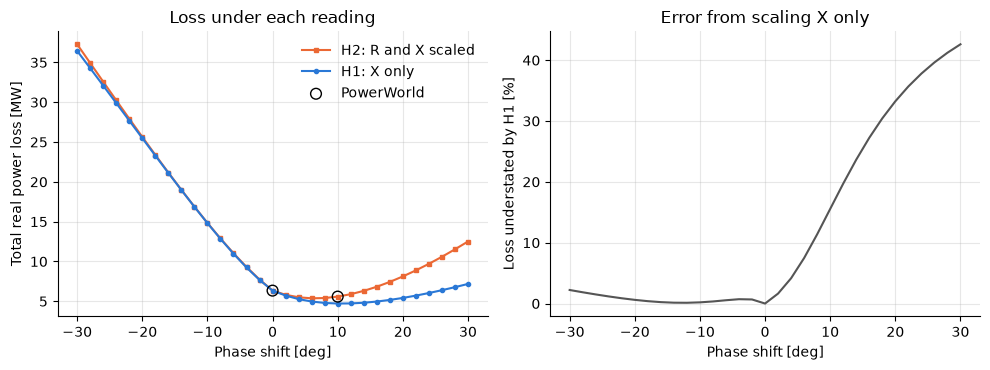

In [4]:
# 5. How far apart the two readings drift across the full tap range
sweep = []
for a in range(-30, 31, 2):
    h1, h2 = results(build_case(a, False)), results(build_case(a, True))
    sweep.append({
        "Angle [deg]": a, "k [-]": np.interp(a, CORR_ANGLE, CORR_FACTOR),
        "H1 P loss [MW]": h1["Total P loss [MW]"], "H2 P loss [MW]": h2["Total P loss [MW]"],
        "H1 PST P [MW]": h1["PST sending P [MW]"], "H2 PST P [MW]": h2["PST sending P [MW]"],
        "H1 Load Bus [kV]": h1["Load Bus voltage [kV]"], "H2 Load Bus [kV]": h2["Load Bus voltage [kV]"],
    })
sweep = pd.DataFrame(sweep)
sweep["Loss understated by H1 [%]"] = (1 - sweep["H1 P loss [MW]"] / sweep["H2 P loss [MW]"]) * 100
sweep["Voltage error of H1 [kV]"] = sweep["H1 Load Bus [kV]"] - sweep["H2 Load Bus [kV]"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(sweep["Angle [deg]"], sweep["H2 P loss [MW]"], marker="s", ms=3, color="#eb6834", label="H2: R and X scaled")
ax1.plot(sweep["Angle [deg]"], sweep["H1 P loss [MW]"], marker="o", ms=3, color="#2a78d6", label="H1: X only")
ax1.scatter([0, 10], [6.340, 5.588], s=60, facecolors="none", edgecolors="black", zorder=3, label="PowerWorld")
ax1.set(xlabel="Phase shift [deg]", ylabel="Total real power loss [MW]", title="Loss under each reading")
ax1.legend(frameon=False)
ax2.plot(sweep["Angle [deg]"], sweep["Loss understated by H1 [%]"], color="#555555")
ax2.set(xlabel="Phase shift [deg]", ylabel="Loss understated by H1 [%]", title="Error from scaling X only")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("Images/Week2_ex3_correction_r_scaling_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# 6. Error at a few angles a planner would actually dial in
sweep[sweep["Angle [deg]"].isin([-30, -20, -10, 0, 10, 20, 30])][[
    "Angle [deg]", "k [-]", "H1 P loss [MW]", "H2 P loss [MW]", "Loss understated by H1 [%]",
    "Voltage error of H1 [kV]", "H1 PST P [MW]", "H2 PST P [MW]",
]].round(3).reset_index(drop=True)

,Angle [deg],k [-],H1 P loss [MW],H2 P loss [MW],Loss understated by H1 [%],Voltage error of H1 [kV],H1 PST P [MW],H2 PST P [MW]
0,-30,2.000,36.446,37.275,2.226,-0.494,-186.815,-185.057
1,-20,1.667,25.490,25.645,0.604,-0.199,-95.178,-94.107
2,-10,1.333,14.818,14.847,0.195,0.018,34.965,35.503
3,0,1.000,6.342,6.342,0.000,0.000,221.859,221.859
4,10,1.333,4.718,5.587,15.551,0.320,339.622,340.246
5,20,1.667,5.421,8.121,33.240,0.713,419.446,420.881
6,30,2.000,7.178,12.508,42.609,1.104,470.151,472.686


## Final conclusion

PowerWorld's impedance correction table multiplies the full series impedance of the phase shifter, not just its reactance. Reading it as a reactance-only multiplier still converges and still gives plausible flows, which is what makes it dangerous: at +10° it understates system losses by 16 % and puts the load bus 0.3 kV too high, and by +30° the loss is understated by 43 % with the voltage 1.1 kV off. The error is lopsided: on the negative side the shifter pushes power back and carries far less current, so the missing $I^2 R$ stays near 2 %. A study that only spot-checks small or negative angles would never notice the problem. When a PSS/E or PowerWorld planning case with correction tables is moved into pandapower, the pipeline therefore scales both `vk_percent` and `vkr_percent` in `trafo_characteristic_table` by the same factor, and checks the converted case against at least one non-zero angle, because at 0° the two readings are indistinguishable.